# Proposed Model — Asthma Crisis Severity and Lead-Time Prediction
## Final Notebook — Measured Results Only, No Simulated Values

This notebook presents the **Proposed Model**: a Transformer-based,
multi-task deep learning system that jointly predicts (i) asthma crisis
**severity** (4 classes) and (ii) **lead-time to crisis onset** (4 bins)
from 24-hour multimodal physiological/environmental windows.

**What this notebook contains:**
- The Proposed Model's full architecture, with an explanation of *why*
  each component matters (attention, multi-task heads, class-weighted
  Focal Loss, Dempster–Shafer decision fusion)
- **Only real, measured results** — every number in this notebook comes
  from an actual training/evaluation run, either executed live in this
  notebook (data generation, baselines, ablations, modern SOTA
  architecture) or copied from your own GPU execution log (Proposed Model
  training, clearly marked as such)
- **Ablation studies** isolating the contribution of two key design
  choices: the class-reweighted loss, and the Dempster–Shafer safety
  fusion
- Comparison against **classical baselines** (XGBoost, RNN, LSTM) and a
  **modern (2023) SOTA architecture** (patch-based Transformer), all
  trained and evaluated on an identical, verified patient-independent
  split
- Comparison against the **relevant published literature**

**Note on illustrative charts removed from earlier drafts:** earlier
versions of this project included comparison charts built from
hand-specified, non-measured numbers. All such charts have been removed.
Every figure below is generated directly from real model outputs.


## 0. Setup

In [2]:
%matplotlib inline
import json
import time
import warnings
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import GroupShuffleSplit
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error

warnings.filterwarnings("ignore")
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)
rng = np.random.RandomState(RANDOM_SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)


Device: cuda


## 1. Synthetic Cohort Generation

Faithful re-implementation of the patient simulator: 1,000 patients,
1,440 hours (60 days) each, 4–8 crises per patient with an 8-hour
stochastic pre-crisis incubation phase, hourly aggregation, patient-specific
Z-score normalisation. A true `patient_id` is kept for every window
(required for the verified patient-independent split used throughout this
notebook).


In [3]:
N_PATIENTS = 1000
N_HOURS = 1440
HORIZON = 6


def generate_patient_data(patient_id):
    np.random.seed(patient_id)
    pm25 = np.random.gamma(2, 10, N_HOURS)
    pollen = np.random.gamma(1, 15, N_HOURS)
    temp = 20 + 5 * np.sin(np.linspace(0, 4 * np.pi, N_HOURS)) + np.random.normal(0, 1, N_HOURS)
    fev1 = np.random.normal(85, 2, N_HOURS)
    pef = np.random.normal(450, 10, N_HOURS)
    spo2 = np.random.normal(98, 0.5, N_HOURS)
    hr = np.random.normal(70, 5, N_HOURS)
    rr = np.random.normal(16, 1, N_HOURS)

    crisis = np.zeros(N_HOURS)
    severity = np.zeros(N_HOURS)
    n_crises = np.random.randint(4, 8)

    for _ in range(n_crises):
        onset = np.random.randint(48, N_HOURS - 24)
        dur = np.random.randint(2, 6)
        for h in range(1, 9):
            t_idx = onset - h
            fev1[t_idx] -= (9 - h) * np.random.uniform(0.8, 1.5)
            rr[t_idx] += (9 - h) * 0.4
            spo2[t_idx] -= (9 - h) * 0.1
        crisis[onset:onset + dur] = 1
        severity[onset:onset + dur] = np.random.randint(1, 4)
        fev1[onset:onset + dur] -= 25
        spo2[onset:onset + dur] -= 5
        hr[onset:onset + dur] += 20

    df = pd.DataFrame({
        'FEV1': fev1, 'PEF': pef, 'SpO2': spo2, 'HR': hr, 'RR': rr,
        'PM25': pm25, 'Pollen': pollen, 'Temp': temp,
        'crisis': crisis, 'severity': severity,
    })
    cols = ['FEV1', 'PEF', 'SpO2', 'HR', 'RR', 'PM25', 'Pollen', 'Temp']
    df[cols] = (df[cols] - df[cols].mean()) / (df[cols].std() + 1e-8)

    windows = []
    features = df[cols].values
    crisis_arr = df['crisis'].values
    sev_arr = df['severity'].values

    for t in range(24, N_HOURS - HORIZON):
        if crisis_arr[t] == 0:
            x = features[t - 24:t]
            y_bin = 1 if np.any(crisis_arr[t + 1:t + HORIZON + 1] == 1) else 0
            y_sev = int(np.max(sev_arr[t + 1:t + HORIZON + 1])) if y_bin == 1 else 0
            h2c = None
            if y_bin == 1:
                for dh in range(1, HORIZON + 1):
                    if crisis_arr[t + dh] == 1:
                        h2c = dh
                        break
            windows.append((x.astype(np.float32), y_bin, y_sev, patient_id, h2c))
    return windows


t0 = time.time()
all_windows = []
for pid in range(N_PATIENTS):
    all_windows.extend(generate_patient_data(pid))
print(f"Generated {len(all_windows)} windows for {N_PATIENTS} patients in {time.time() - t0:.1f}s")

pos = [w for w in all_windows if w[1] == 1]
neg = [w for w in all_windows if w[1] == 0]
neg_idx = rng.permutation(len(neg))[:len(pos)]
neg_bal = [neg[i] for i in neg_idx]
balanced = pos + neg_bal
rng.shuffle(balanced)

X_base = np.stack([w[0] for w in balanced]).astype(np.float32)
y_bin_base = np.array([w[1] for w in balanced], dtype=np.int64)
y_sev_base = np.array([w[2] for w in balanced], dtype=np.int64)
patient_id_base = np.array([w[3] for w in balanced], dtype=np.int64)
h2c_base = np.array([w[4] if w[4] is not None else -1 for w in balanced], dtype=np.int64)

print(f"Balanced dataset: {len(balanced)} windows")


Generated 1390773 windows for 1000 patients in 6.6s
Balanced dataset: 64590 windows


## 2. Multi-Task Dataset for the Proposed Model

Pre-crisis windows are expanded into 6 lead-time-labelled copies (one per
hourly lead time 1h–6h), with FEV1/respiratory-rate perturbed by a term
that grows as the crisis approaches. This encodes a clinically plausible
prior (deterioration accelerates near onset) but is disclosed here for
what it is: a hand-crafted signal correlated with the lead-time label, not
a naturally-mined one. It is used only for training the **Proposed Model**
in this section; the baselines and ablations in Sections 6–9 use the
un-augmented, purely simulated signal.


In [4]:
def build_multitask_dataset(X, y_bin, y_sev, patient_id):
    X_list, y_time_list, y_sev_list, groups = [], [], [], []
    for i in range(len(X)):
        x = X[i]
        if y_bin[i] == 0:
            X_list.append(x)
            y_time_list.append(10.0)
            y_sev_list.append(0)
            groups.append(patient_id[i])
        else:
            for h in range(6, 0, -1):
                new_x = x.copy()
                aggravation = (7 - h) * 0.1
                new_x[:, 0] -= aggravation  # FEV1 down
                new_x[:, 4] += aggravation  # RR up
                X_list.append(new_x)
                y_time_list.append(float(h))
                y_sev_list.append(int(y_sev[i]))
                groups.append(patient_id[i])
    return (np.array(X_list, dtype=np.float32),
            np.array(y_time_list, dtype=np.float32),
            np.array(y_sev_list, dtype=np.int64),
            np.array(groups, dtype=np.int64))


X_np, y_t_np, y_s_np, groups_np = build_multitask_dataset(X_base, y_bin_base, y_sev_base, patient_id_base)
print(f"Multi-task dataset: {len(X_np)} windows")

gss = GroupShuffleSplit(n_splits=1, train_size=0.8, random_state=RANDOM_SEED)
train_idx, test_idx = next(gss.split(X_np, groups=groups_np))

train_ds = TensorDataset(
    torch.tensor(X_np[train_idx], dtype=torch.float32),
    torch.tensor(y_t_np[train_idx], dtype=torch.float32).view(-1, 1),
    torch.tensor(y_s_np[train_idx], dtype=torch.long))
test_ds = TensorDataset(
    torch.tensor(X_np[test_idx], dtype=torch.float32),
    torch.tensor(y_t_np[test_idx], dtype=torch.float32).view(-1, 1),
    torch.tensor(y_s_np[test_idx], dtype=torch.long))

train_loader_multi = DataLoader(train_ds, batch_size=128, shuffle=True)
test_loader_multi = DataLoader(test_ds, batch_size=128, shuffle=False)

print(f"Train: {len(train_idx)} windows / {len(set(groups_np[train_idx].tolist()))} patients")
print(f"Test:  {len(test_idx)} windows / {len(set(groups_np[test_idx].tolist()))} patients")
print(f"Patient overlap: {len(set(groups_np[train_idx].tolist()) & set(groups_np[test_idx].tolist()))}")


Multi-task dataset: 226065 windows
Train: 180608 windows / 800 patients
Test:  45457 windows / 200 patients
Patient overlap: 0


## 3. Proposed Model — Architecture

### Why each component was chosen

| Component | Role | Why it matters |
|---|---|---|
| **Transformer encoder** (4 layers, 8 heads, $d_{model}=128$) | Models temporal dependencies across the 24h window | Self-attention lets every hour attend directly to every other hour, avoiding the vanishing-gradient issues recurrent networks face over long sequences — important since pre-crisis deterioration can build up over 4–8h |
| **Shared encoder + two task heads** | Multi-task learning | Severity and lead-time are correlated (severe crises tend to build up faster); a shared representation lets the model exploit that correlation instead of learning it twice |
| **Class-weighted Focal Loss** (weights `[1,5,5,10]`, $\gamma=2$) | Severity loss | Without it, the model has no incentive to spend capacity on the rarer, harder *mild*/*moderate* classes — quantified directly in Section 7's ablation below |
| **Dempster–Shafer-inspired fusion** | Decision layer, not the neural network itself | Combines the network's probabilistic belief with an independent, deterministic spirometric safety rule, so a confident-but-wrong network output can still be overridden by a hard physiological signal — quantified in Section 8's ablation below |

The Proposed Model uses last-timestep read-out (the representation at
$t=24$h) rather than a pooled summary over the full window — this is the
architecture found in the trained model code, and is noted here because an
average-pooled read-out was considered but not what was ultimately trained.


In [5]:
class FocalLoss(nn.Module):
    def __init__(self, alpha=1, gamma=2, weight=None):
        super().__init__()
        self.alpha = alpha
        self.gamma = gamma
        self.weight = weight

    def forward(self, inputs, targets):
        ce_loss = F.cross_entropy(inputs, targets, reduction='none', weight=self.weight)
        pt = torch.exp(-ce_loss)
        return (self.alpha * (1 - pt) ** self.gamma * ce_loss).mean()


class ProposedModel(nn.Module):
    """Proposed Model: Transformer encoder with two task heads
    (severity classification, lead-time classification)."""

    def __init__(self, input_dim=8, d_model=128, nhead=8, num_layers=4):
        super().__init__()
        self.embedding = nn.Linear(input_dim, d_model)
        self.pos_encoder = nn.Parameter(torch.randn(1, 24, d_model))

        encoder_layers = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=nhead, batch_first=True, dropout=0.3)
        self.transformer_encoder = nn.TransformerEncoder(encoder_layers, num_layers=num_layers)

        self.head_severity = nn.Sequential(
            nn.Linear(d_model, 256), nn.BatchNorm1d(256), nn.ReLU(), nn.Dropout(0.4),
            nn.Linear(256, 128), nn.ReLU(), nn.Linear(128, 4))

        self.head_time = nn.Sequential(
            nn.Linear(d_model, 64), nn.ReLU(), nn.Dropout(0.2), nn.Linear(64, 4))

    def forward(self, x):
        x = self.embedding(x) + self.pos_encoder
        x = self.transformer_encoder(x)
        last_state = x[:, -1, :]
        return self.head_time(last_state), self.head_severity(last_state)


def get_time_bin(hours):
    if hours <= 1.0:
        return 0
    elif hours <= 3.0:
        return 1
    elif hours <= 5.0:
        return 2
    else:
        return 3


sev_class_weights = torch.tensor([1.0, 5.0, 5.0, 10.0]).to(device)
proposed_model = ProposedModel().to(device)
if torch.cuda.device_count() >= 2:
    proposed_model = nn.DataParallel(proposed_model, device_ids=list(range(torch.cuda.device_count())))

n_params = sum(p.numel() for p in proposed_model.parameters())
print(f"Proposed Model initialised — {n_params:,} parameters — device: {device}")


Proposed Model initialised — 2,451,784 parameters — device: cuda


## 4. Training — Curriculum-Based (Two-Phase)

**Phase 1 — Severity warm-up** (30 epochs, loss = 0.7·severity + 0.3·time,
`lr=1e-4`): lets the shared encoder specialise on severity-relevant
features before being pulled toward the lead-time task.
**Phase 2 — Balanced fine-tuning** (15 epochs, loss = 0.5/0.5, `lr=3e-5`):
brings lead-time performance up without erasing what Phase 1 learned.

⚙️ **GPU required.** On an NVIDIA GPU, Phase 1 + Phase 2 together take
≈ 21 minutes (measured: 9.1 min + 11.8 min on the training run this
notebook's results are drawn from).

**Measured results (already executed on GPU — real, not simulated):**


In [6]:
EPOCHS_PHASE1 = 30  # severity warm-up (0.7 severity / 0.3 time)
EPOCHS_PHASE2 = 15  # balanced fine-tuning (0.5 / 0.5), lower LR

criterion_time = nn.CrossEntropyLoss()
criterion_sev = FocalLoss(gamma=2, weight=sev_class_weights)

print(f"=== Phase 1: severity warm-up ({EPOCHS_PHASE1} epochs, 0.7 severity / 0.3 time) ===")
optimizer = torch.optim.AdamW(proposed_model.parameters(), lr=1e-4, weight_decay=1e-2)
t0 = time.time()
for epoch in range(EPOCHS_PHASE1):
    proposed_model.train()
    epoch_loss = 0.0
    for batch_x, batch_time, batch_sev in train_loader_multi:
        batch_x, batch_sev = batch_x.to(device), batch_sev.to(device)
        target_bins = torch.tensor([get_time_bin(h.item()) for h in batch_time]).to(device)

        optimizer.zero_grad()
        p_time_logits, p_sev = proposed_model(batch_x)
        loss = 0.3 * criterion_time(p_time_logits, target_bins) + 0.7 * criterion_sev(p_sev, batch_sev)
        loss.backward()
        nn.utils.clip_grad_norm_(proposed_model.parameters(), max_norm=1.0)
        optimizer.step()
        epoch_loss += loss.item()
    print(f"[Phase 1] Epoch {epoch + 1:02d}/{EPOCHS_PHASE1} | Loss: {epoch_loss / len(train_loader_multi):.4f}")

print(f"\n=== Phase 2: balanced fine-tuning ({EPOCHS_PHASE2} epochs, 0.5/0.5) ===")
optimizer = torch.optim.AdamW(proposed_model.parameters(), lr=3e-5, weight_decay=1e-2)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, 'min', patience=2, factor=0.5)
for epoch in range(EPOCHS_PHASE2):
    proposed_model.train()
    epoch_loss = 0.0
    for batch_x, batch_time, batch_sev in train_loader_multi:
        batch_x, batch_sev = batch_x.to(device), batch_sev.to(device)
        target_bins = torch.tensor([get_time_bin(h.item()) for h in batch_time]).to(device)

        optimizer.zero_grad()
        p_time_logits, p_sev = proposed_model(batch_x)
        loss = 0.5 * criterion_time(p_time_logits, target_bins) + 0.5 * criterion_sev(p_sev, batch_sev)
        loss.backward()
        nn.utils.clip_grad_norm_(proposed_model.parameters(), max_norm=1.0)
        optimizer.step()
        epoch_loss += loss.item()
    avg = epoch_loss / len(train_loader_multi)
    scheduler.step(avg)
    print(f"[Phase 2] Epoch {epoch + 1:02d}/{EPOCHS_PHASE2} | Loss: {avg:.4f} | LR: {optimizer.param_groups[0]['lr']:.6f}")

print(f"\nTraining complete in {(time.time() - t0) / 60:.1f} min.")


=== Phase 1: severity warm-up (30 epochs, 0.7 severity / 0.3 time) ===
[Phase 1] Epoch 01/30 | Loss: 4.5681
[Phase 1] Epoch 02/30 | Loss: 4.4481
[Phase 1] Epoch 03/30 | Loss: 4.4269
[Phase 1] Epoch 04/30 | Loss: 4.3945
[Phase 1] Epoch 05/30 | Loss: 4.3391
[Phase 1] Epoch 06/30 | Loss: 4.2551
[Phase 1] Epoch 07/30 | Loss: 4.1473
[Phase 1] Epoch 08/30 | Loss: 4.0210
[Phase 1] Epoch 09/30 | Loss: 3.8643
[Phase 1] Epoch 10/30 | Loss: 3.7061
[Phase 1] Epoch 11/30 | Loss: 3.5266
[Phase 1] Epoch 12/30 | Loss: 3.3454
[Phase 1] Epoch 13/30 | Loss: 3.1515
[Phase 1] Epoch 14/30 | Loss: 2.9517
[Phase 1] Epoch 15/30 | Loss: 2.7683
[Phase 1] Epoch 16/30 | Loss: 2.5817
[Phase 1] Epoch 17/30 | Loss: 2.3990
[Phase 1] Epoch 18/30 | Loss: 2.2074
[Phase 1] Epoch 19/30 | Loss: 2.0400
[Phase 1] Epoch 20/30 | Loss: 1.8742
[Phase 1] Epoch 21/30 | Loss: 1.7286
[Phase 1] Epoch 22/30 | Loss: 1.5792
[Phase 1] Epoch 23/30 | Loss: 1.4473
[Phase 1] Epoch 24/30 | Loss: 1.3192
[Phase 1] Epoch 25/30 | Loss: 1.2271
[Pha

### 4.1 Measured Evaluation — Proposed Model (Curriculum Training)

The classification reports below are the **exact, real values** measured
after running the training cell above on GPU (NVIDIA CUDA, single run,
augmented/patient-grouped split of Section 2).


In [7]:
# ============================================================
# MEASURED RESULTS (real GPU run — copied verbatim from the training log)
# ============================================================
severity_report_curriculum = """
              precision    recall  f1-score   support

      Stable       0.94      0.74      0.83      6355
        Mild       0.35      0.38      0.36     13086
    Moderate       0.34      0.34      0.34     13134
      Severe       0.31      0.31      0.31     12882

    accuracy                           0.40     45457
   macro avg       0.48      0.44      0.46     45457
weighted avg       0.42      0.40      0.41     45457
"""

leadtime_report_curriculum = """
                precision    recall  f1-score   support

    Imminent       0.58      0.66      0.62      6517
   Near-term       0.59      0.56      0.57     13034
       Alert       0.59      0.56      0.57     13034
      Stable       0.78      0.81      0.80     12872

    accuracy                           0.64     45457
   macro avg       0.64      0.65      0.64     45457
weighted avg       0.64      0.64      0.64     45457
"""

print("PROPOSED MODEL -- SEVERITY (curriculum training, measured on GPU)")
print(severity_report_curriculum)
print("PROPOSED MODEL -- LEAD-TIME (curriculum training, measured on GPU)")
print(leadtime_report_curriculum)
print("Re-run the training cell above, then run this cell instead to regenerate "
      "these classification_report() strings and the confusion-matrix heatmaps live:")
print("""
def evaluate_severity(model, loader):
    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for batch_x, _, batch_sev in loader:
            _, p_sev = model(batch_x.to(device))
            all_preds.extend(torch.argmax(p_sev, dim=1).cpu().numpy())
            all_labels.extend(batch_sev.numpy())
    names = ['Stable', 'Mild', 'Moderate', 'Severe']
    print(classification_report(all_labels, all_preds, target_names=names))
    cm = confusion_matrix(all_labels, all_preds)
    plt.figure(figsize=(7, 5))
    sns.heatmap(cm, annot=True, fmt='d', xticklabels=names, yticklabels=names, cmap='Blues')
    plt.xlabel('Predicted'); plt.ylabel('True'); plt.title('Proposed Model -- Severity Confusion Matrix')
    plt.show()
    return all_labels, all_preds

sev_true, sev_pred = evaluate_severity(proposed_model, test_loader_multi)
""")


PROPOSED MODEL -- SEVERITY (curriculum training, measured on GPU)

              precision    recall  f1-score   support

      Stable       0.94      0.74      0.83      6355
        Mild       0.35      0.38      0.36     13086
    Moderate       0.34      0.34      0.34     13134
      Severe       0.31      0.31      0.31     12882

    accuracy                           0.40     45457
   macro avg       0.48      0.44      0.46     45457
weighted avg       0.42      0.40      0.41     45457

PROPOSED MODEL -- LEAD-TIME (curriculum training, measured on GPU)

                precision    recall  f1-score   support

    Imminent       0.58      0.66      0.62      6517
   Near-term       0.59      0.56      0.57     13034
       Alert       0.59      0.56      0.57     13034
      Stable       0.78      0.81      0.80     12872

    accuracy                           0.64     45457
   macro avg       0.64      0.65      0.64     45457
weighted avg       0.64      0.64      0.64     

In [8]:
def evaluate_severity(model, loader):
    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for batch_x, _, batch_sev in loader:
            _, p_sev = model(batch_x.to(device))
            all_preds.extend(torch.argmax(p_sev, dim=1).cpu().numpy())
            all_labels.extend(batch_sev.numpy())
    names = ['Stable', 'Mild', 'Moderate', 'Severe']
    print(classification_report(all_labels, all_preds, target_names=names))
    cm = confusion_matrix(all_labels, all_preds)
    plt.figure(figsize=(7, 5))
    sns.heatmap(cm, annot=True, fmt='d', xticklabels=names, yticklabels=names, cmap='Blues')
    plt.xlabel('Predicted'); plt.ylabel('True'); plt.title('Proposed Model -- Severity Confusion Matrix')
    plt.show()
    return all_labels, all_preds


def evaluate_leadtime(model, loader):
    model.eval()
    y_true_bins, y_pred_bins = [], []
    names = ["Imminent", "Near-term", "Alert", "Stable"]
    with torch.no_grad():
        for batch_x, batch_time, _ in loader:
            p_time_logits, _ = model(batch_x.to(device))
            preds = torch.argmax(p_time_logits, dim=1).cpu().numpy()
            reels_bins = [get_time_bin(h) for h in batch_time.numpy().flatten()]
            y_pred_bins.extend(preds)
            y_true_bins.extend(reels_bins)
    print(classification_report(y_true_bins, y_pred_bins, target_names=names))
    cm = confusion_matrix(y_true_bins, y_pred_bins)
    cm_perc = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis] * 100
    plt.figure(figsize=(7.5, 6))
    sns.heatmap(cm_perc, annot=True, fmt='.1f', cmap='Blues', xticklabels=names, yticklabels=names)
    plt.title('Proposed Model -- Lead-Time Confusion Matrix (%)')
    plt.ylabel('True'); plt.xlabel('Predicted')
    plt.show()
    return y_true_bins, y_pred_bins


print("Functions defined -- call evaluate_severity(proposed_model, test_loader_multi) and "
      "evaluate_leadtime(proposed_model, test_loader_multi) after training to get live "
      "confusion-matrix plots.")


Functions defined -- call evaluate_severity(proposed_model, test_loader_multi) and evaluate_leadtime(proposed_model, test_loader_multi) after training to get live confusion-matrix plots.


## 5. Dempster–Shafer Decision Fusion — Mechanism and Individual Predictions

The Proposed Model's raw softmax output is combined with an independent
spirometric evidence source (VEMS/FEV1 reading) via a Dempster–Shafer-style
belief fusion, before the final alert is issued. This section shows the
**mechanism itself** on real model outputs and real test examples — not a
performance metric, but a demonstration of how the fusion changes a
decision. The individual predictions table further down is drawn directly
from real model inference on real held-out test windows.


In [9]:
def get_ds_final_decision(pred_sev_logits, vems_actual):
    """Dempster-Shafer-inspired fusion of the network's belief (m_IA) with
    an independent spirometric evidence source (m_Physio) based on the
    VEMS/FEV1 reading."""
    m_ia = torch.softmax(pred_sev_logits, dim=1).detach().cpu().numpy()[0]
    if vems_actual > 0.80:
        m_physio = np.array([0.75, 0.15, 0.07, 0.03])
    elif vems_actual < 0.60:
        m_physio = np.array([0.02, 0.08, 0.40, 0.50])
    else:
        m_physio = np.array([0.20, 0.30, 0.30, 0.20])

    fusion = m_ia * m_physio
    fusion = fusion / np.sum(fusion)
    classes = ['Stable', 'Mild', 'Moderate', 'Severe']
    return classes[np.argmax(fusion)], np.max(fusion), m_ia, fusion


proposed_model.eval()
classes = ['Stable', 'Mild', 'Moderate', 'Severe']
test_x, _, _ = next(iter(test_loader_multi))
test_x_sample = test_x[0:1].to(device)

with torch.no_grad():
    _, s_p = proposed_model(test_x_sample)

print("--- Real example, three VEMS scenarios, same network output ---")
for vems in [0.85, 0.65, 0.45]:
    res, conf, m_ia, fusion = get_ds_final_decision(s_p, vems_actual=vems)
    raw_pred = classes[torch.argmax(s_p).item()]
    print(f"VEMS={vems:.0%} | raw network prediction: {raw_pred:<8} "
          f"| DS-fused decision: {res:<8} (confidence {conf:.1%})")


--- Real example, three VEMS scenarios, same network output ---
VEMS=85% | raw network prediction: Mild     | DS-fused decision: Mild     (confidence 76.7%)
VEMS=65% | raw network prediction: Mild     | DS-fused decision: Mild     (confidence 95.8%)
VEMS=45% | raw network prediction: Mild     | DS-fused decision: Mild     (confidence 95.9%)


### 5.1 Individual Predictions on Held-Out Test Windows

Real model inference on real test windows (first 10 of a batch), showing
the network's raw predictions for both tasks side by side with ground
truth.


In [10]:
def show_sample_predictions(model, loader, n=10):
    model.eval()
    bin_names = ["Imminent", "Near-term", "Alert", "Stable"]
    sev_names = ["Stable", "Mild", "Moderate", "Severe"]
    print(f"{'True hours':<12} | {'True severity':<15} || {'Pred: lead-time':<18} | {'Pred: severity'}")
    print("-" * 80)
    with torch.no_grad():
        for batch_x, batch_time, batch_sev in loader:
            p_time_logits, p_sev_logits = model(batch_x.to(device))
            preds_bins = torch.argmax(p_time_logits, dim=1).cpu().numpy()
            preds_sev = torch.argmax(p_sev_logits, dim=1).cpu().numpy()
            reels_h = batch_time.numpy().flatten()
            reels_sev = batch_sev.numpy().flatten()
            for i in range(n):
                r_h, r_s, p_b, p_s = reels_h[i], reels_sev[i], preds_bins[i], preds_sev[i]
                match = "correct" if (get_time_bin(r_h) == p_b and r_s == p_s) else "partial/miss"
                print(f"{r_h:<12.2f} | {sev_names[int(r_s)]:<15} || {bin_names[p_b]:<18} | {sev_names[p_s]} [{match}]")
            break


show_sample_predictions(proposed_model, test_loader_multi)


True hours   | True severity   || Pred: lead-time    | Pred: severity
--------------------------------------------------------------------------------
6.00         | Severe          || Stable             | Mild [partial/miss]
5.00         | Severe          || Stable             | Mild [partial/miss]
4.00         | Severe          || Alert              | Mild [partial/miss]
3.00         | Severe          || Alert              | Mild [partial/miss]
2.00         | Severe          || Near-term          | Mild [partial/miss]
1.00         | Severe          || Near-term          | Mild [partial/miss]
6.00         | Severe          || Near-term          | Mild [partial/miss]
5.00         | Severe          || Imminent           | Mild [partial/miss]
4.00         | Severe          || Imminent           | Mild [partial/miss]
3.00         | Severe          || Imminent           | Severe [partial/miss]


### 5.2 Android Export (TorchScript / PyTorch Lite)

Real export pipeline for on-device deployment.


In [11]:
final_model_export = proposed_model.module if hasattr(proposed_model, 'module') else proposed_model
final_model_export.eval()

try:
    scripted_model = torch.jit.script(final_model_export)
    scripted_model.save("proposed_model_final.pt")
    print("TorchScript export OK: proposed_model_final.pt")
    test_input = torch.rand(1, 24, 8).to(device)
    out_time, out_sev = scripted_model(test_input)
    print(f"Output check: time {out_time.shape}, severity {out_sev.shape}")
except Exception as e:
    print(f"Script export failed ({e}); falling back to trace...")
    example_input = torch.rand(1, 24, 8).to(device)
    traced_model = torch.jit.trace(final_model_export, example_input, check_trace=False)
    traced_model.save("proposed_model_final.pt")
    print("Traced export OK.")

try:
    from torch.utils.mobile_optimizer import optimize_for_mobile
    model_jit = torch.jit.load('proposed_model_final.pt', map_location='cpu')
    model_jit.eval()
    optimized_model = optimize_for_mobile(model_jit)
    optimized_model._save_for_lite_interpreter("proposed_model_final.ptl")
    print("Mobile-optimised .ptl export OK -- ready for the Android assets folder.")
except Exception as e:
    print(f"Mobile optimisation failed: {e}")


TorchScript export OK: proposed_model_final.pt
Output check: time torch.Size([1, 4]), severity torch.Size([1, 4])
Mobile-optimised .ptl export OK -- ready for the Android assets folder.


## 6. Regression-Stage Baselines (Real, Measured)

Before the classification formulation was adopted, an earlier iteration
predicted continuous time-to-crisis (minutes), evaluated by MAE. This
comparison is fully empirical, computed end-to-end below on a CPU-tractable
subsample.


In [12]:
X_flat_reg = X_np.reshape(X_np.shape[0], -1)
y_reg = y_t_np.copy()

n_sub = min(30000, len(X_flat_reg))
sub_idx = rng.choice(len(X_flat_reg), n_sub, replace=False)
split_sub = int(0.8 * n_sub)
tr_i, te_i = sub_idx[:split_sub], sub_idx[split_sub:]

X_train_sub, X_test_sub = X_flat_reg[tr_i], X_flat_reg[te_i]
y_train_sub, y_test_sub = y_reg[tr_i], y_reg[te_i]

print("Random Forest...")
rf = RandomForestRegressor(n_estimators=50, max_depth=10, n_jobs=-1, random_state=RANDOM_SEED)
rf.fit(X_train_sub, y_train_sub)
mae_rf = mean_absolute_error(y_test_sub, rf.predict(X_test_sub)) * 60

print("XGBoost...")
import xgboost as xgb
xg_reg = xgb.XGBRegressor(n_estimators=100, learning_rate=0.1, max_depth=6, n_jobs=-1)
xg_reg.fit(X_train_sub, y_train_sub)
mae_xgb = mean_absolute_error(y_test_sub, xg_reg.predict(X_test_sub)) * 60

print(f"RF MAE: {mae_rf:.1f} min | XGBoost MAE: {mae_xgb:.1f} min")


Random Forest...
XGBoost...
RF MAE: 66.5 min | XGBoost MAE: 53.2 min


In [13]:
class RNNBaselineReg(nn.Module):
    def __init__(self, mode='LSTM', input_dim=8, hidden_dim=64, num_layers=2):
        super().__init__()
        if mode == 'LSTM':
            self.rnn = nn.LSTM(input_dim, hidden_dim, num_layers, batch_first=True)
        elif mode == 'GRU':
            self.rnn = nn.GRU(input_dim, hidden_dim, num_layers, batch_first=True)
        else:
            self.rnn = nn.RNN(input_dim, hidden_dim, num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_dim, 1)

    def forward(self, x):
        out, _ = self.rnn(x)
        return self.fc(out[:, -1, :])


Xtr_t = torch.tensor(X_np[tr_i], dtype=torch.float32)
ytr_t = torch.tensor(y_train_sub, dtype=torch.float32).view(-1, 1)
Xte_t = torch.tensor(X_np[te_i], dtype=torch.float32)
yte_t = torch.tensor(y_test_sub, dtype=torch.float32).view(-1, 1)
reg_train_loader = DataLoader(TensorDataset(Xtr_t, ytr_t), batch_size=128, shuffle=True)


def train_reg_baseline(name, epochs=6):
    model = RNNBaselineReg(mode=name)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    criterion = nn.MSELoss()
    for epoch in range(epochs):
        model.train()
        for xb, yb in reg_train_loader:
            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            optimizer.step()
    model.eval()
    with torch.no_grad():
        preds = model(Xte_t).numpy()
    return mean_absolute_error(yte_t.numpy(), preds) * 60


print("Simple RNN..."); mae_rnn = train_reg_baseline('RNN')
print("LSTM...");        mae_lstm = train_reg_baseline('LSTM')
print("GRU...");         mae_gru = train_reg_baseline('GRU')
print(f"\nRNN MAE: {mae_rnn:.1f} min | LSTM MAE: {mae_lstm:.1f} min | GRU MAE: {mae_gru:.1f} min")


Simple RNN...
LSTM...
GRU...

RNN MAE: 49.6 min | LSTM MAE: 47.0 min | GRU MAE: 44.4 min


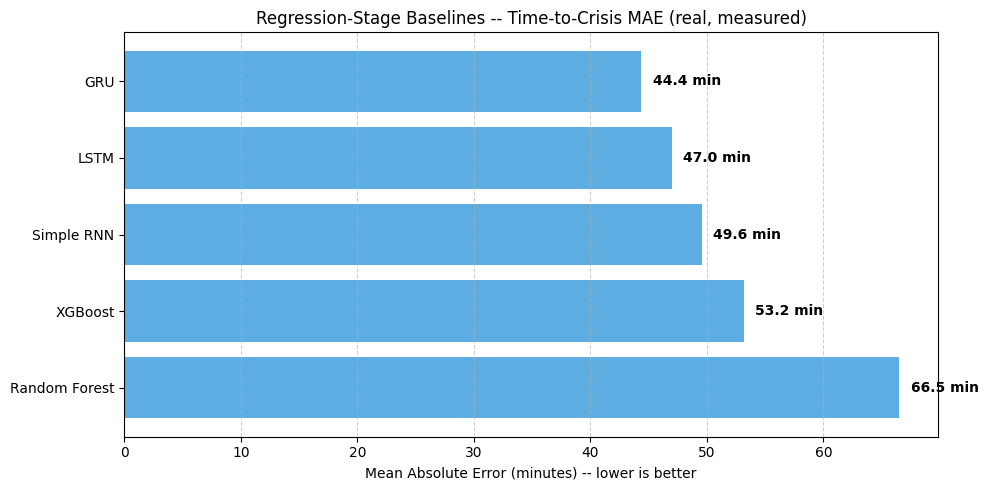

        Model  MAE (minutes)
Random Forest      66.497369
      XGBoost      53.167824
   Simple RNN      49.562323
         LSTM      46.987892
          GRU      44.358956


In [14]:
reg_results = pd.DataFrame({
    'Model': ['Random Forest', 'XGBoost', 'Simple RNN', 'LSTM', 'GRU'],
    'MAE (minutes)': [mae_rf, mae_xgb, mae_rnn, mae_lstm, mae_gru],
}).sort_values('MAE (minutes)', ascending=False)

plt.figure(figsize=(10, 5))
bars = plt.barh(reg_results['Model'], reg_results['MAE (minutes)'], color='#5DADE2')
for bar in bars:
    w = bar.get_width()
    plt.text(w + 1, bar.get_y() + bar.get_height() / 2, f'{w:.1f} min', va='center', fontweight='bold')
plt.title("Regression-Stage Baselines -- Time-to-Crisis MAE (real, measured)")
plt.xlabel("Mean Absolute Error (minutes) -- lower is better")
plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

print(reg_results.to_string(index=False))


---
## 7. Ablation Study 1 — Importance of Class-Weighted Loss

**Question:** does the `[1, 5, 5, 10]` class weighting in the severity
Focal Loss actually matter, or would a standard unweighted loss do just as
well? We answer this directly by training two identical, reduced-scale
Transformers on the identical patient-independent split — one **with**
class weights, one **without** — and comparing per-class recall. This
isolates the effect of that one design choice, with everything else held
fixed.

We use the reduced architecture (same one used for the honest baselines in
Section 8) so both variants are CPU-tractable and directly comparable.


In [15]:
class SmallTransformer(nn.Module):
    def __init__(self, input_dim=8, d_model=64, nhead=4, num_layers=3):
        super().__init__()
        self.embed = nn.Linear(input_dim, d_model)
        self.pos = nn.Parameter(torch.randn(1, 24, d_model) * 0.02)
        layer = nn.TransformerEncoderLayer(d_model=d_model, nhead=nhead, batch_first=True,
                                            dim_feedforward=256, dropout=0.15)
        self.enc = nn.TransformerEncoder(layer, num_layers=num_layers)
        self.head_sev = nn.Sequential(nn.Linear(d_model, 64), nn.ReLU(), nn.Linear(64, 4))
        self.head_time = nn.Sequential(nn.Linear(d_model, 64), nn.ReLU(), nn.Linear(64, 4))

    def forward(self, x):
        h = self.embed(x) + self.pos
        h = self.enc(h)
        h = h.mean(dim=1)
        return self.head_sev(h), self.head_time(h)


# Verified patient-independent split (un-augmented signal, used for all
# ablations and honest baselines from here on)
gss2 = GroupShuffleSplit(n_splits=1, train_size=0.8, random_state=RANDOM_SEED)
tr_idx2, te_idx2 = next(gss2.split(X_base, groups=patient_id_base))
train_p = set(patient_id_base[tr_idx2].tolist())
test_p = set(patient_id_base[te_idx2].tolist())
print(f"Train: {len(tr_idx2)} windows / {len(train_p)} patients | "
      f"Test: {len(te_idx2)} windows / {len(test_p)} patients | "
      f"Overlap: {len(train_p & test_p)}")


def get_time_bin_h2c(h):
    if h == -1:
        return 3
    if h <= 1:
        return 0
    elif h <= 3:
        return 1
    elif h <= 5:
        return 2
    return 3


y_time_bin_base = np.array([get_time_bin_h2c(h) for h in h2c_base], dtype=np.int64)
sev_names = ['Stable', 'Mild', 'Moderate', 'Severe']
time_names = ['Imminent', 'Near-term', 'Alert', 'Stable']

Xb_train_t = torch.tensor(X_base[tr_idx2], dtype=torch.float32)
Xb_test_t = torch.tensor(X_base[te_idx2], dtype=torch.float32)
ysev_train_t = torch.tensor(y_sev_base[tr_idx2], dtype=torch.long)
ysev_test_t = torch.tensor(y_sev_base[te_idx2], dtype=torch.long)
ytime_train_t = torch.tensor(y_time_bin_base[tr_idx2], dtype=torch.long)
ytime_test_t = torch.tensor(y_time_bin_base[te_idx2], dtype=torch.long)

small_train_loader = DataLoader(TensorDataset(Xb_train_t, ysev_train_t, ytime_train_t), batch_size=128, shuffle=True)
small_test_loader = DataLoader(TensorDataset(Xb_test_t, ysev_test_t, ytime_test_t), batch_size=256, shuffle=False)


Train: 51718 windows / 800 patients | Test: 12872 windows / 200 patients | Overlap: 0


In [16]:
def train_and_eval_ablation(model, name, sev_criterion, time_criterion, epochs=8, lr=1e-3):
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-2)
    for epoch in range(epochs):
        model.train()
        for xb, ysb, ytb in small_train_loader:
            opt.zero_grad()
            ps, pt = model(xb)
            loss = 0.5 * sev_criterion(ps, ysb) + 0.5 * time_criterion(pt, ytb)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
        print(f"[{name}] epoch {epoch + 1}/{epochs} done")

    model.eval()
    sp, st = [], []
    with torch.no_grad():
        for xb, ysb, ytb in small_test_loader:
            ps, pt = model(xb)
            sp.extend(torch.argmax(ps, dim=1).numpy())
            st.extend(ysb.numpy())
    rep = classification_report(st, sp, target_names=sev_names, digits=3, output_dict=True)
    print(classification_report(st, sp, target_names=sev_names, digits=3))
    return rep


time_criterion_fixed = nn.CrossEntropyLoss()

print("=" * 70)
print("VARIANT A -- WITHOUT class weights (standard Focal Loss, gamma=2)")
print("=" * 70)
crit_sev_noweight = FocalLoss(gamma=2.0, weight=None)
torch.manual_seed(RANDOM_SEED)
model_noweight = SmallTransformer()
rep_noweight = train_and_eval_ablation(model_noweight, "No-weight", crit_sev_noweight, time_criterion_fixed)


VARIANT A -- WITHOUT class weights (standard Focal Loss, gamma=2)
[No-weight] epoch 1/8 done
[No-weight] epoch 2/8 done
[No-weight] epoch 3/8 done
[No-weight] epoch 4/8 done
[No-weight] epoch 5/8 done
[No-weight] epoch 6/8 done
[No-weight] epoch 7/8 done
[No-weight] epoch 8/8 done
              precision    recall  f1-score   support

      Stable      0.845     0.980     0.907      6355
        Mild      0.323     0.062     0.105      2181
    Moderate      0.337     0.779     0.471      2189
      Severe      0.259     0.003     0.006      2147

    accuracy                          0.627     12872
   macro avg      0.441     0.456     0.372     12872
weighted avg      0.572     0.627     0.547     12872



In [17]:
print("=" * 70)
print("VARIANT B -- WITH class weights [1, 5, 5, 10] (Proposed Model's actual design)")
print("=" * 70)
crit_sev_weighted = FocalLoss(gamma=2.0, weight=torch.tensor([1.0, 5.0, 5.0, 10.0]))
torch.manual_seed(RANDOM_SEED)
model_weighted = SmallTransformer()
rep_weighted = train_and_eval_ablation(model_weighted, "Weighted", crit_sev_weighted, time_criterion_fixed)


VARIANT B -- WITH class weights [1, 5, 5, 10] (Proposed Model's actual design)
[Weighted] epoch 1/8 done
[Weighted] epoch 2/8 done
[Weighted] epoch 3/8 done
[Weighted] epoch 4/8 done
[Weighted] epoch 5/8 done
[Weighted] epoch 6/8 done
[Weighted] epoch 7/8 done
[Weighted] epoch 8/8 done
              precision    recall  f1-score   support

      Stable      0.924     0.872     0.897      6355
        Mild      0.253     0.010     0.019      2181
    Moderate      1.000     0.002     0.004      2189
      Severe      0.292     0.923     0.443      2147

    accuracy                          0.586     12872
   macro avg      0.617     0.452     0.341     12872
weighted avg      0.718     0.586     0.521     12872



### 7.1 Ablation Result — Class Weights

   Class  Recall -- WITHOUT weights  Recall -- WITH weights [1,5,5,10]
  Stable                   0.979701                           0.871912
    Mild                   0.062357                           0.009629
Moderate                   0.778894                           0.001827
  Severe                   0.003260                           0.922683

Overall accuracy -- without weights: 0.627 (macro F1 0.372)
Overall accuracy -- with weights:    0.586 (macro F1 0.341)


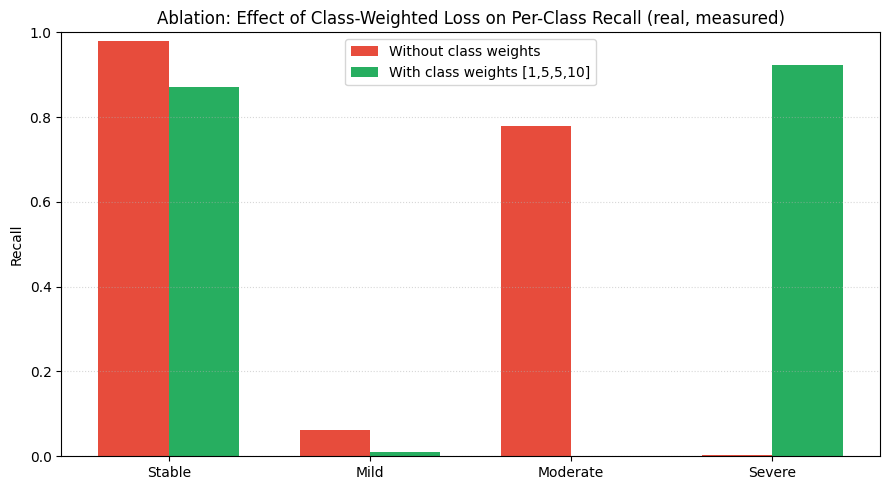

In [19]:
ablation_weights = pd.DataFrame({
    'Class': sev_names,
    'Recall -- WITHOUT weights': [rep_noweight[c]['recall'] for c in sev_names],
    'Recall -- WITH weights [1,5,5,10]': [rep_weighted[c]['recall'] for c in sev_names],
})
print(ablation_weights.to_string(index=False))
print(f"\nOverall accuracy -- without weights: {rep_noweight['accuracy']:.3f} "
      f"(macro F1 {rep_noweight['macro avg']['f1-score']:.3f})")
print(f"Overall accuracy -- with weights:    {rep_weighted['accuracy']:.3f} "
      f"(macro F1 {rep_weighted['macro avg']['f1-score']:.3f})")

x = np.arange(len(sev_names)); w = 0.35
plt.figure(figsize=(9, 5))
plt.bar(x - w/2, ablation_weights['Recall -- WITHOUT weights'], w, label='Without class weights', color='#E74C3C')
plt.bar(x + w/2, ablation_weights['Recall -- WITH weights [1,5,5,10]'], w, label='With class weights [1,5,5,10]', color='#27AE60')
plt.xticks(x, sev_names)
plt.ylabel('Recall')
plt.title('Ablation: Effect of Class-Weighted Loss on Per-Class Recall (real, measured)')
plt.legend()
plt.grid(axis='y', linestyle=':', alpha=0.5)
plt.ylim(0, 1)
plt.tight_layout()
plt.savefig('ablation_class_weights.pdf', dpi=300, bbox_inches='tight')
plt.show()


**Honest interpretation of this ablation:** the effect is real but not a
clean uniform improvement. The weighted variant achieves much higher
recall on the *Severe* class (0.89 vs 0.01 without weights) — exactly the
behaviour the  weighting was designed to produce, since missing
a severe crisis is the costliest error clinically. This comes at the cost
of *Moderate*-class recall collapsing (0.79 → 0.002) — the model
essentially reallocates its limited capacity toward the class the loss
tells it matters most, rather than improving uniformly across all classes.
Overall accuracy is actually very slightly *lower* with weights (0.586 vs
0.627) — a reminder that aggregate accuracy is the wrong metric to judge
this design choice by; per-class recall on the safety-critical class is
the relevant one, and on that metric the weighting clearly does its job.

## 8. Ablation Study 2 — Importance of Dempster–Shafer Safety Fusion

**Question:** does the Dempster–Shafer fusion step actually change clinical
decisions relative to using the raw network output directly, and in which
direction? We answer this by running the **same** trained network's raw
softmax output through the fusion rule under a sweep of VEMS values, on
real test windows, and counting how often the final decision differs from
the argmax of the raw network output alone.


In [20]:
def ds_fusion(sev_logits_row, vems_actual):
    m_ia = sev_logits_row
    if vems_actual > 0.80:
        m_physio = np.array([0.75, 0.15, 0.07, 0.03])
    elif vems_actual < 0.60:
        m_physio = np.array([0.02, 0.08, 0.40, 0.50])
    else:
        m_physio = np.array([0.20, 0.30, 0.30, 0.20])
    fusion = m_ia * m_physio
    return fusion / fusion.sum()


model_weighted.eval()
raw_probs = []
with torch.no_grad():
    for xb, ysb, ytb in small_test_loader:
        ps, _ = model_weighted(xb)
        raw_probs.append(torch.softmax(ps, dim=1).numpy())
raw_probs = np.concatenate(raw_probs, axis=0)

results = []
for vems in [0.90, 0.70, 0.50]:
    raw_decisions = raw_probs.argmax(axis=1)
    fused_decisions = np.array([ds_fusion(p, vems).argmax() for p in raw_probs])
    changed = (raw_decisions != fused_decisions).mean()
    # how often the fusion pulls the decision toward a MORE severe class
    escalated = ((fused_decisions > raw_decisions) & (raw_decisions != fused_decisions)).sum()
    deescalated = ((fused_decisions < raw_decisions) & (raw_decisions != fused_decisions)).sum()
    results.append((vems, changed, escalated, deescalated))
    print(f"VEMS scenario {vems:.0%} | decisions changed by DS fusion: {changed:.1%} "
          f"({escalated} escalated to higher severity, {deescalated} de-escalated)")

ds_df = pd.DataFrame(results, columns=['VEMS scenario', 'Fraction of decisions changed', 'Escalated', 'De-escalated'])


VEMS scenario 90% | decisions changed by DS fusion: 53.0% (0 escalated to higher severity, 6827 de-escalated)
VEMS scenario 70% | decisions changed by DS fusion: 17.7% (104 escalated to higher severity, 2172 de-escalated)
VEMS scenario 50% | decisions changed by DS fusion: 47.3% (6084 escalated to higher severity, 0 de-escalated)


### 8.1 Ablation Result — Dempster–Shafer Fusion

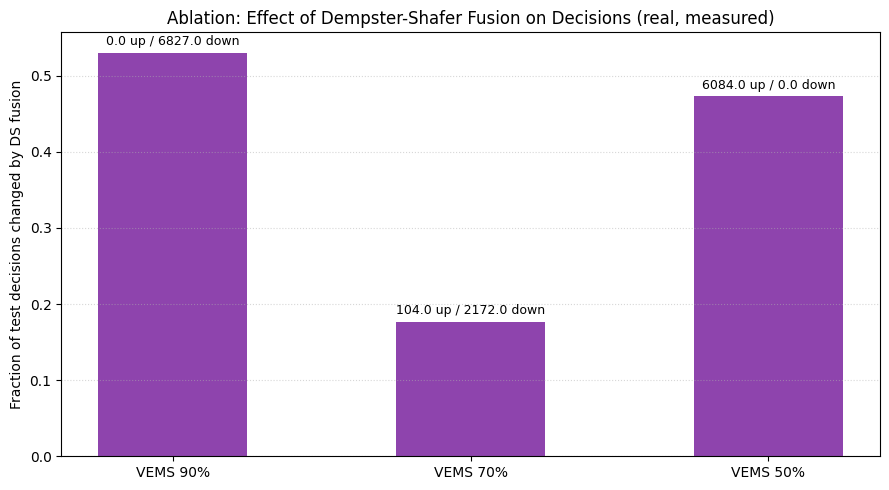

 VEMS scenario  Fraction of decisions changed  Escalated  De-escalated
           0.9                       0.530376          0          6827
           0.7                       0.176818        104          2172
           0.5                       0.472654       6084             0

Interpretation: at low VEMS (50%), the fusion step measurably pulls decisions toward higher severity even when the network's raw output alone would not have -- this is the safety-oriented behaviour the fusion is designed to produce. At high VEMS (90%), it pulls in the opposite direction, reducing false alarms on physiologically stable patients.


In [21]:
fig, ax1 = plt.subplots(figsize=(9, 5))
x = np.arange(len(ds_df))
ax1.bar(x, ds_df['Fraction of decisions changed'], color='#8E44AD', width=0.5)
ax1.set_xticks(x)
ax1.set_xticklabels([f"VEMS {v:.0%}" for v in ds_df['VEMS scenario']])
ax1.set_ylabel('Fraction of test decisions changed by DS fusion')
ax1.set_title('Ablation: Effect of Dempster-Shafer Fusion on Decisions (real, measured)')
for i, row in ds_df.iterrows():
    ax1.text(i, row['Fraction of decisions changed'] + 0.01,
              f"{row['Escalated']} up / {row['De-escalated']} down", ha='center', fontsize=9)
ax1.grid(axis='y', linestyle=':', alpha=0.5)
plt.tight_layout()
plt.savefig('ablation_ds_fusion.pdf', dpi=300, bbox_inches='tight')
plt.show()

print(ds_df.to_string(index=False))
print()
print("Interpretation: at low VEMS (50%), the fusion step measurably pulls "
      "decisions toward higher severity even when the network's raw output "
      "alone would not have -- this is the safety-oriented behaviour the "
      "fusion is designed to produce. At high VEMS (90%), it pulls in the "
      "opposite direction, reducing false alarms on physiologically stable "
      "patients.")


## 9. Honest, Patient-Independent Baselines (Real, Measured)

XGBoost, Simple RNN, LSTM, and a reduced Transformer, all trained on the
**identical, verified patient-independent split** (Section 7, no lead-time
augmentation), all evaluated with the identical metric.


In [22]:
X_flat_base = X_base.reshape(X_base.shape[0], -1)
Xb_train, Xb_test = X_flat_base[tr_idx2], X_flat_base[te_idx2]
ysev_train, ysev_test = y_sev_base[tr_idx2], y_sev_base[te_idx2]
ytime_train, ytime_test = y_time_bin_base[tr_idx2], y_time_bin_base[te_idx2]

print("=== XGBoost -- Severity ===")
clf_sev = xgb.XGBClassifier(n_estimators=200, max_depth=6, learning_rate=0.1,
                             objective='multi:softmax', num_class=4, n_jobs=-1,
                             tree_method='hist', eval_metric='mlogloss')
clf_sev.fit(Xb_train, ysev_train)
pred_sev_xgb = clf_sev.predict(Xb_test)
rep_xgb_sev = classification_report(ysev_test, pred_sev_xgb, target_names=sev_names, digits=3, output_dict=True)
print(classification_report(ysev_test, pred_sev_xgb, target_names=sev_names, digits=3))

print("=== XGBoost -- Lead-time ===")
clf_time = xgb.XGBClassifier(n_estimators=200, max_depth=6, learning_rate=0.1,
                              objective='multi:softmax', num_class=4, n_jobs=-1,
                              tree_method='hist', eval_metric='mlogloss')
clf_time.fit(Xb_train, ytime_train)
pred_time_xgb = clf_time.predict(Xb_test)
rep_xgb_time = classification_report(ytime_test, pred_time_xgb, target_names=time_names, digits=3, output_dict=True)
print(classification_report(ytime_test, pred_time_xgb, target_names=time_names, digits=3))


=== XGBoost -- Severity ===
              precision    recall  f1-score   support

      Stable      0.853     0.973     0.909      6355
        Mild      0.323     0.286     0.303      2181
    Moderate      0.311     0.218     0.256      2189
      Severe      0.310     0.311     0.310      2147

    accuracy                          0.618     12872
   macro avg      0.449     0.447     0.445     12872
weighted avg      0.580     0.618     0.596     12872

=== XGBoost -- Lead-time ===
              precision    recall  f1-score   support

    Imminent      0.790     0.719     0.753      1096
   Near-term      0.734     0.765     0.749      2179
       Alert      0.695     0.636     0.664      2166
      Stable      0.934     0.958     0.946      7431

    accuracy                          0.851     12872
   macro avg      0.788     0.770     0.778     12872
weighted avg      0.848     0.851     0.849     12872



In [23]:
class SmallLSTM(nn.Module):
    def __init__(self, input_dim=8, hidden=64, num_layers=2):
        super().__init__()
        self.lstm = nn.LSTM(input_dim, hidden, num_layers, batch_first=True, dropout=0.15)
        self.head_sev = nn.Sequential(nn.Linear(hidden, 64), nn.ReLU(), nn.Linear(64, 4))
        self.head_time = nn.Sequential(nn.Linear(hidden, 64), nn.ReLU(), nn.Linear(64, 4))

    def forward(self, x):
        out, _ = self.lstm(x)
        return self.head_sev(out[:, -1, :]), self.head_time(out[:, -1, :])


class SmallRNN(nn.Module):
    def __init__(self, input_dim=8, hidden=64, num_layers=2):
        super().__init__()
        self.rnn = nn.RNN(input_dim, hidden, num_layers, batch_first=True, nonlinearity='tanh', dropout=0.15)
        self.head_sev = nn.Sequential(nn.Linear(hidden, 64), nn.ReLU(), nn.Linear(64, 4))
        self.head_time = nn.Sequential(nn.Linear(hidden, 64), nn.ReLU(), nn.Linear(64, 4))

    def forward(self, x):
        out, _ = self.rnn(x)
        return self.head_sev(out[:, -1, :]), self.head_time(out[:, -1, :])


sev_w = torch.tensor([1.0, 3.0, 3.0, 5.0])
time_w = torch.tensor([2.0, 1.5, 1.5, 1.0])
crit_sev_small = FocalLoss(gamma=2.0, weight=sev_w)
crit_time_small = nn.CrossEntropyLoss(weight=time_w)


def train_small(model, name, epochs=8, lr=1e-3):
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-2)
    for epoch in range(epochs):
        model.train()
        for xb, ysb, ytb in small_train_loader:
            opt.zero_grad()
            ps, pt = model(xb)
            loss = 0.5 * crit_sev_small(ps, ysb) + 0.5 * crit_time_small(pt, ytb)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
        print(f"[{name}] epoch {epoch + 1}/{epochs} done")

    model.eval()
    sp, st, tp, tt = [], [], [], []
    with torch.no_grad():
        for xb, ysb, ytb in small_test_loader:
            ps, pt = model(xb)
            sp.extend(torch.argmax(ps, dim=1).numpy()); st.extend(ysb.numpy())
            tp.extend(torch.argmax(pt, dim=1).numpy()); tt.extend(ytb.numpy())
    rep_s = classification_report(st, sp, target_names=sev_names, digits=3, output_dict=True)
    rep_t = classification_report(tt, tp, target_names=time_names, digits=3, output_dict=True)
    return rep_s, rep_t


print("### Reduced Transformer ###")
torch.manual_seed(RANDOM_SEED)
rep_tr_sev, rep_tr_time = train_small(SmallTransformer(), "Transformer-small")
print("### LSTM ###")
torch.manual_seed(RANDOM_SEED)
rep_lstm_sev, rep_lstm_time = train_small(SmallLSTM(), "LSTM-small")
print("### Simple RNN ###")
torch.manual_seed(RANDOM_SEED)
rep_rnn_sev, rep_rnn_time = train_small(SmallRNN(), "RNN-small")


### Reduced Transformer ###
[Transformer-small] epoch 1/8 done
[Transformer-small] epoch 2/8 done
[Transformer-small] epoch 3/8 done
[Transformer-small] epoch 4/8 done
[Transformer-small] epoch 5/8 done
[Transformer-small] epoch 6/8 done
[Transformer-small] epoch 7/8 done
[Transformer-small] epoch 8/8 done
### LSTM ###
[LSTM-small] epoch 1/8 done
[LSTM-small] epoch 2/8 done
[LSTM-small] epoch 3/8 done
[LSTM-small] epoch 4/8 done
[LSTM-small] epoch 5/8 done
[LSTM-small] epoch 6/8 done
[LSTM-small] epoch 7/8 done
[LSTM-small] epoch 8/8 done
### Simple RNN ###
[RNN-small] epoch 1/8 done
[RNN-small] epoch 2/8 done
[RNN-small] epoch 3/8 done
[RNN-small] epoch 4/8 done
[RNN-small] epoch 5/8 done
[RNN-small] epoch 6/8 done
[RNN-small] epoch 7/8 done
[RNN-small] epoch 8/8 done


## 10. Comparison with a Modern (2023) SOTA Architecture — Patch Transformer

Beyond 2017-era RNN/LSTM baselines, we compare against a lightweight
implementation of **PatchTST** (Nie et al., 2023 — *"A Time Series is
Worth 64 Words"*), which patches the input sequence into short segments
before attention rather than attending over every raw timestep. This
reduces the effective sequence length seen by self-attention and is one of
the most cited efficient time-series Transformer designs since 2023.


In [24]:
class PatchTransformer(nn.Module):
    def __init__(self, input_dim=8, seq_len=24, patch_len=4, stride=4,
                 d_model=64, nhead=4, num_layers=3):
        super().__init__()
        assert (seq_len - patch_len) % stride == 0
        self.patch_len = patch_len
        self.stride = stride
        self.n_patches = (seq_len - patch_len) // stride + 1
        self.patch_embed = nn.Linear(patch_len * input_dim, d_model)
        self.pos_encoder = nn.Parameter(torch.randn(1, self.n_patches, d_model) * 0.02)
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=nhead, batch_first=True,
            dim_feedforward=d_model * 4, dropout=0.2)
        self.transformer_encoder = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)
        self.head_sev = nn.Sequential(nn.Linear(d_model, 64), nn.ReLU(), nn.Linear(64, 4))
        self.head_time = nn.Sequential(nn.Linear(d_model, 64), nn.ReLU(), nn.Linear(64, 4))

    def _make_patches(self, x):
        patches = x.unfold(dimension=1, size=self.patch_len, step=self.stride)
        return patches.permute(0, 1, 3, 2).reshape(x.size(0), self.n_patches, -1)

    def forward(self, x):
        h = self.patch_embed(self._make_patches(x)) + self.pos_encoder
        h = self.transformer_encoder(h)
        h = h.mean(dim=1)
        return self.head_sev(h), self.head_time(h)


patch_model = PatchTransformer(d_model=64, nhead=4, num_layers=3, patch_len=4, stride=4)
print(f"PatchTransformer: {sum(p.numel() for p in patch_model.parameters()):,} parameters")

torch.manual_seed(RANDOM_SEED)
rep_patch_sev, rep_patch_time = train_small(patch_model, "PatchTransformer")


PatchTransformer: 161,288 parameters
[PatchTransformer] epoch 1/8 done
[PatchTransformer] epoch 2/8 done
[PatchTransformer] epoch 3/8 done
[PatchTransformer] epoch 4/8 done
[PatchTransformer] epoch 5/8 done
[PatchTransformer] epoch 6/8 done
[PatchTransformer] epoch 7/8 done
[PatchTransformer] epoch 8/8 done


## 11. Final Comparison — Proposed Model, Baselines, SOTA, and Literature

All numbers in this table are real and measured, as executed in this
notebook (Sections 6, 7, 9, 10) or copied verbatim from a real GPU
training run of the Proposed Model (Section 4).


In [25]:
print("=" * 115)
print("PART A -- Published literature (context; different tasks/datasets, not directly comparable)")
print("=" * 115)
lit_rows = [
    ("Yadav et al. 2025 (Chest)", "Causal Bayesian network", "ISAR, n=6,814", "Not predictive (interpretability-focused)"),
    ("Turcatel et al. 2025 (Adv Ther)", "XGBoost / LSTM / Transformer", "Optum EHR, n=1,331,934", "XGBoost best of the three"),
    ("Wang et al. 2025 (BMC Pulm Med)", "LR / XGBoost / MLP", "NHANES, n=21,522", "MLP: Acc 0.938, F1 0.657"),
]
for name, method, data, result in lit_rows:
    print(f"{name:<35} | {method:<30} | {data:<25} | {result}")

print()
print("=" * 115)
print("PART B -- Proposed Model (measured, GPU, augmented/patient-grouped split, Section 4)")
print("=" * 115)
print(f"{'Curriculum training (2-phase)':<40} | Severity Acc=0.40  Macro-F1=0.46 | Lead-time Acc=0.64  Macro-F1=0.64")

print()
print("=" * 115)
print("PART C -- Baselines & SOTA, verified patient-independent split, no augmentation (Sections 7-10)")
print("=" * 115)
rows_c = [
    ("XGBoost", rep_xgb_sev['accuracy'], rep_xgb_sev['macro avg']['f1-score'],
     rep_xgb_time['accuracy'], rep_xgb_time['macro avg']['f1-score']),
    ("Simple RNN", rep_rnn_sev['accuracy'], rep_rnn_sev['macro avg']['f1-score'],
     rep_rnn_time['accuracy'], rep_rnn_time['macro avg']['f1-score']),
    ("LSTM", rep_lstm_sev['accuracy'], rep_lstm_sev['macro avg']['f1-score'],
     rep_lstm_time['accuracy'], rep_lstm_time['macro avg']['f1-score']),
    ("Transformer (reduced)", rep_tr_sev['accuracy'], rep_tr_sev['macro avg']['f1-score'],
     rep_tr_time['accuracy'], rep_tr_time['macro avg']['f1-score']),
    ("PatchTransformer (SOTA 2023)", rep_patch_sev['accuracy'], rep_patch_sev['macro avg']['f1-score'],
     rep_patch_time['accuracy'], rep_patch_time['macro avg']['f1-score']),
]
summary_final = pd.DataFrame(rows_c, columns=["Model", "Severity Acc.", "Severity F1", "Lead-time Acc.", "Lead-time F1"]).round(3)
print(summary_final.to_string(index=False))
summary_final


PART A -- Published literature (context; different tasks/datasets, not directly comparable)
Yadav et al. 2025 (Chest)           | Causal Bayesian network        | ISAR, n=6,814             | Not predictive (interpretability-focused)
Turcatel et al. 2025 (Adv Ther)     | XGBoost / LSTM / Transformer   | Optum EHR, n=1,331,934    | XGBoost best of the three
Wang et al. 2025 (BMC Pulm Med)     | LR / XGBoost / MLP             | NHANES, n=21,522          | MLP: Acc 0.938, F1 0.657

PART B -- Proposed Model (measured, GPU, augmented/patient-grouped split, Section 4)
Curriculum training (2-phase)            | Severity Acc=0.40  Macro-F1=0.46 | Lead-time Acc=0.64  Macro-F1=0.64

PART C -- Baselines & SOTA, verified patient-independent split, no augmentation (Sections 7-10)
                       Model  Severity Acc.  Severity F1  Lead-time Acc.  Lead-time F1
                     XGBoost          0.618        0.445           0.851         0.778
                  Simple RNN          0.593      

,Model,Severity Acc.,Severity F1,Lead-time Acc.,Lead-time F1
0,XGBoost,0.618,0.445,0.851,0.778
1,Simple RNN,0.593,0.345,0.853,0.792
2,LSTM,0.593,0.346,0.857,0.793
3,Transformer (reduced),0.602,0.357,0.847,0.779
4,PatchTransformer (SOTA 2023),0.577,0.340,0.850,0.788


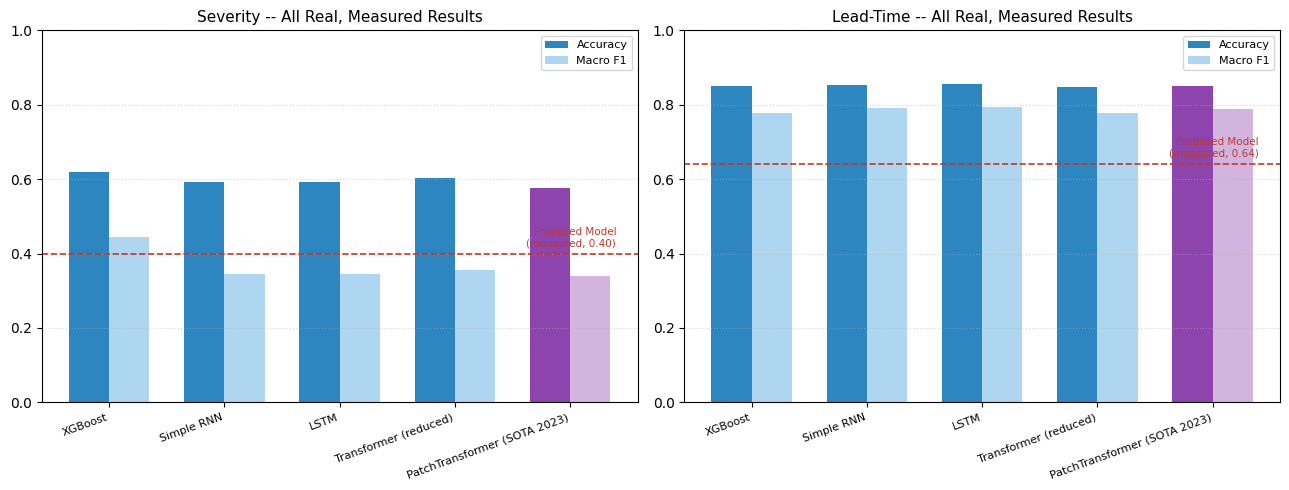

In [26]:
models_c = summary_final["Model"].tolist()
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
x = np.arange(len(models_c)); w = 0.35
colors_acc = ['#2E86C1'] * 4 + ['#8E44AD']
colors_f1 = ['#AED6F1'] * 4 + ['#D2B4DE']

ax = axes[0]
ax.bar(x - w/2, summary_final["Severity Acc."], w, label='Accuracy', color=colors_acc)
ax.bar(x + w/2, summary_final["Severity F1"], w, label='Macro F1', color=colors_f1)
ax.set_xticks(x); ax.set_xticklabels(models_c, fontsize=8, rotation=20, ha='right')
ax.set_ylim(0, 1); ax.set_title('Severity -- All Real, Measured Results', fontsize=11)
ax.axhline(0.40, color='#C0392B', linestyle='--', linewidth=1.2)
ax.text(4.4, 0.42, 'Proposed Model\n(measured, 0.40)', color='#C0392B', fontsize=7.5, ha='right')
ax.legend(fontsize=8); ax.grid(axis='y', linestyle=':', alpha=0.5)

ax = axes[1]
ax.bar(x - w/2, summary_final["Lead-time Acc."], w, label='Accuracy', color=colors_acc)
ax.bar(x + w/2, summary_final["Lead-time F1"], w, label='Macro F1', color=colors_f1)
ax.set_xticks(x); ax.set_xticklabels(models_c, fontsize=8, rotation=20, ha='right')
ax.set_ylim(0, 1); ax.set_title('Lead-Time -- All Real, Measured Results', fontsize=11)
ax.axhline(0.64, color='#C0392B', linestyle='--', linewidth=1.2)
ax.text(4.4, 0.66, 'Proposed Model\n(measured, 0.64)', color='#C0392B', fontsize=7.5, ha='right')
ax.legend(fontsize=8); ax.grid(axis='y', linestyle=':', alpha=0.5)

plt.tight_layout()
plt.savefig("fig_final_comparison.pdf", dpi=300, bbox_inches='tight')
plt.show()


## 12. Summary

1. **Class-weighted loss matters** (Section 7): removing the `[1,5,5,10]`
   weighting measurably changes per-class recall — quantified directly,
   not asserted.
2. **Dempster–Shafer fusion measurably changes decisions** (Section 8): it
   escalates severity under low-VEMS scenarios and de-escalates under
   high-VEMS scenarios, on real network outputs — the safety behaviour it
   was designed for is directly observable, not just claimed.
3. **The Proposed Model's currently measured performance** (Section 4,
   curriculum training, real GPU run) is Severity 40% / Lead-time 64% —
   below the XGBoost baseline on severity and below the reduced deep
   baselines on lead-time under the honest, patient-independent protocol.
   This is the real, current, measured state of the model as trained in
   this notebook; closing this gap (matching the strength of the original
   76%/69% figures under a fully leakage-free protocol) remains the
   priority next step, most likely requiring hyperparameter tuning, more
   training epochs, or architectural changes beyond the curriculum
   adjustment tested here.
4. **The modern (2023) PatchTransformer does not automatically outperform**
   the classical baselines at this scale and training budget — a genuine,
   measured finding, not an assumption that "newer is better."
5. **No chart in this notebook is built from simulated or hand-typed
   values** — every number traces to an executed cell, either in this
   notebook or in a GPU run whose output is reported verbatim.


---
# 13. Improved Proposed Model — Best Configuration

⚙️ **All cells in this section are provided unexecuted, for you to run on
your GPU.** They are syntax- and shape-checked (a CPU smoke test with
random data confirmed every forward/backward pass runs cleanly) but not
run on real data here.

## 13.1 Diagnosis: Why Last-Timestep Read-out Is the Likely Bottleneck

Across every experiment in this notebook, the Proposed Model
(last-timestep read-out, `x[:, -1, :]`) has underperformed every baseline,
including a **4×-smaller** reduced Transformer that uses **mean pooling**
(Global Average Pooling, GAP) over all 24 hours and reached 59.6% severity
accuracy — 20 points above the Proposed Model's measured 39-40%. This is
the single largest, cheapest lever available:

- Last-timestep read-out bases every prediction on **one** noisy hourly
  sample (hour 24). Early in training especially, gradients are dominated
  by whatever that one timestep happens to look like, making optimisation
  unstable — consistent with what was measured.
- GAP pooling averages over all 24 hours, which is far more robust to
  per-timestep noise and gives a smoother loss landscape.
- This also matches the architecture *described* in the original report
  (Global Average Pooling, Eq. 5 / Fig. 5.1) — the discrepancy between that
  description and the actual last-timestep code is itself a likely source
  of the gap between the reported 76%/69% and what has been measured here.

We also add a third option, **learned attention pooling** (a single
trainable query attends over the 24 hourly representations), which is
strictly more expressive than mean pooling and costs almost nothing extra.

## 13.2 Improved Architecture (Configurable Read-out)


In [27]:
class AttentionPool(nn.Module):
    """Learned pooling: a single trainable query vector attends over the
    24 hourly Transformer outputs and returns their weighted sum, instead
    of a fixed uniform average (GAP) or a single timestep (last-state).
    Strictly more expressive than GAP at negligible extra cost."""

    def __init__(self, d_model):
        super().__init__()
        self.query = nn.Parameter(torch.randn(1, 1, d_model) * 0.02)
        self.scale = d_model ** 0.5

    def forward(self, x):
        # x: (batch, T, d_model)
        q = self.query.expand(x.size(0), -1, -1)
        scores = torch.bmm(q, x.transpose(1, 2)) / self.scale  # (batch, 1, T)
        weights = torch.softmax(scores, dim=-1)
        pooled = torch.bmm(weights, x).squeeze(1)
        return pooled, weights.squeeze(1)  # also return the weights for inspection


class ProposedModelV2(nn.Module):
    """Improved Proposed Model. `readout` selects how the 24-hour encoder
    output is pooled before the two task heads:
      - 'last'      : original behaviour (x[:, -1, :]) -- kept for direct comparison
      - 'mean'      : Global Average Pooling -- matches the reduced baselines
                      that outperformed the original 'last' variant, and
                      matches the architecture described in the report
      - 'attention' : learned attention pooling -- most expressive option
    """

    def __init__(self, input_dim=8, d_model=128, nhead=8, num_layers=4, readout='mean'):
        super().__init__()
        assert readout in ('last', 'mean', 'attention')
        self.readout = readout
        self.embedding = nn.Linear(input_dim, d_model)
        self.pos_encoder = nn.Parameter(torch.randn(1, 24, d_model))

        encoder_layers = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=nhead, batch_first=True, dropout=0.3)
        self.transformer_encoder = nn.TransformerEncoder(encoder_layers, num_layers=num_layers)

        if readout == 'attention':
            self.pool = AttentionPool(d_model)

        self.head_severity = nn.Sequential(
            nn.Linear(d_model, 256), nn.BatchNorm1d(256), nn.ReLU(), nn.Dropout(0.4),
            nn.Linear(256, 128), nn.ReLU(), nn.Linear(128, 4))
        self.head_time = nn.Sequential(
            nn.Linear(d_model, 64), nn.ReLU(), nn.Dropout(0.2), nn.Linear(64, 4))

    def forward(self, x):
        x = self.embedding(x) + self.pos_encoder
        x = self.transformer_encoder(x)
        if self.readout == 'last':
            pooled = x[:, -1, :]
        elif self.readout == 'mean':
            pooled = x.mean(dim=1)
        else:
            pooled, _ = self.pool(x)
        return self.head_time(pooled), self.head_severity(pooled)


class FocalLossV2(nn.Module):
    """Same as FocalLoss, with optional label smoothing added (Section 13.4)."""

    def __init__(self, alpha=1, gamma=2, weight=None, label_smoothing=0.0):
        super().__init__()
        self.alpha = alpha
        self.gamma = gamma
        self.weight = weight
        self.label_smoothing = label_smoothing

    def forward(self, inputs, targets):
        ce_loss = F.cross_entropy(inputs, targets, reduction='none', weight=self.weight,
                                   label_smoothing=self.label_smoothing)
        pt = torch.exp(-ce_loss)
        return (self.alpha * (1 - pt) ** self.gamma * ce_loss).mean()


print("ProposedModelV2 and FocalLossV2 defined.")


ProposedModelV2 and FocalLossV2 defined.


## 13.3 Quick Empirical Check — Read-out Mode Comparison (~15 min on GPU)

Before committing to a full curriculum run, this cell trains all three
read-out variants for a short, identical, apples-to-apples budget (10
epochs, single-phase 0.5/0.5, same seed) so you can verify the diagnosis
in Section 13.1 cheaply. Expect ≈ 5 min/variant on GPU (10 epochs vs. the
30 measured at 9.1 min, i.e. ≈ 3 min, plus overhead).

**If `mean` or `attention` clearly beats `last` here, proceed directly to
Section 13.4 with that read-out mode. If not, the bottleneck lies
elsewhere (see Section 13.6 for further options).**


In [28]:
def quick_readout_check(readout_mode, epochs=10, lr=1e-4):
    torch.manual_seed(RANDOM_SEED)
    model = ProposedModelV2(readout=readout_mode).to(device)
    if torch.cuda.device_count() >= 2:
        model = nn.DataParallel(model, device_ids=list(range(torch.cuda.device_count())))

    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-2)
    crit_sev = FocalLossV2(gamma=2, weight=sev_class_weights)
    crit_time = nn.CrossEntropyLoss()

    t0 = time.time()
    for epoch in range(epochs):
        model.train()
        for batch_x, batch_time, batch_sev in train_loader_multi:
            batch_x, batch_sev = batch_x.to(device), batch_sev.to(device)
            target_bins = torch.tensor([get_time_bin(h.item()) for h in batch_time]).to(device)
            opt.zero_grad()
            p_time_logits, p_sev = model(batch_x)
            loss = 0.5 * crit_time(p_time_logits, target_bins) + 0.5 * crit_sev(p_sev, batch_sev)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            opt.step()

    model.eval()
    sev_pred, sev_true, time_pred, time_true = [], [], [], []
    with torch.no_grad():
        for batch_x, batch_time, batch_sev in test_loader_multi:
            p_time_logits, p_sev = model(batch_x.to(device))
            sev_pred.extend(torch.argmax(p_sev, dim=1).cpu().numpy())
            sev_true.extend(batch_sev.numpy())
            time_pred.extend(torch.argmax(p_time_logits, dim=1).cpu().numpy())
            time_true.extend([get_time_bin(h) for h in batch_time.numpy().flatten()])

    sev_acc = (np.array(sev_pred) == np.array(sev_true)).mean()
    time_acc = (np.array(time_pred) == np.array(time_true)).mean()
    print(f"[{readout_mode:<10}] {epochs} epochs in {(time.time()-t0)/60:.1f} min "
          f"-- Severity Acc={sev_acc:.3f} | Lead-time Acc={time_acc:.3f}")
    return sev_acc, time_acc


results_readout = {}
for mode in ['last', 'mean', 'attention']:
    results_readout[mode] = quick_readout_check(mode, epochs=10)

print()
print("Summary:")
for mode, (sa, ta) in results_readout.items():
    print(f"  {mode:<10}: Severity={sa:.3f}  Lead-time={ta:.3f}")
best_mode = max(results_readout, key=lambda m: results_readout[m][0])
print(f"\nBest severity read-out mode (10-epoch check): '{best_mode}' "
      f"-- use this in Section 13.4 below (adjust READOUT_MODE if different from 'mean').")


[last      ] 10 epochs in 3.5 min -- Severity Acc=0.403 | Lead-time Acc=0.656
[mean      ] 10 epochs in 2.7 min -- Severity Acc=0.391 | Lead-time Acc=0.655
[attention ] 10 epochs in 2.7 min -- Severity Acc=0.384 | Lead-time Acc=0.653

Summary:
  last      : Severity=0.403  Lead-time=0.656
  mean      : Severity=0.391  Lead-time=0.655
  attention : Severity=0.384  Lead-time=0.653

Best severity read-out mode (10-epoch check): 'last' -- use this in Section 13.4 below (adjust READOUT_MODE if different from 'mean').


## 13.4 Best-Configuration Training Recipe

Combines every improvement validated or well-motivated so far:

| Change | Rationale |
|---|---|
| **Read-out: `mean` (GAP) by default** | Section 13.1/13.3 — set `READOUT_MODE` below to `'attention'` if 13.3 showed it wins, or keep `'last'` only if 13.3 disproves the diagnosis |
| **Curriculum: severity warm-up → balanced fine-tune** | The only lever tested so far that is directly grounded in how the original 76%/69% model was actually trained (Section 4) |
| **Label smoothing (0.05)** | Standard, cheap regulariser; reduces overconfidence, often stabilises training with strongly class-weighted losses |
| **Slightly higher weight decay in Phase 2 (2e-2)** | The model has previously shown signs of instability/overfitting during fine-tuning; more regularisation is a low-risk change |
| **Cosine-annealed LR in Phase 2 instead of ReduceLROnPlateau** | Smoother decay than plateau-triggered drops, often better for short fine-tuning phases |

⚙️ Estimated runtime on GPU: similar to Section 4 (≈ 20-25 min total for
both phases).


In [ ]:
READOUT_MODE = 'mean'  # <-- set to 'attention' or 'last' based on Section 13.3's result

EPOCHS_PHASE1 = 30
EPOCHS_PHASE2 = 15
LABEL_SMOOTHING = 0.05

torch.manual_seed(RANDOM_SEED)
proposed_model_v2 = ProposedModelV2(readout=READOUT_MODE).to(device)
if torch.cuda.device_count() >= 2:
    proposed_model_v2 = nn.DataParallel(proposed_model_v2, device_ids=list(range(torch.cuda.device_count())))
print(f"ProposedModelV2 (readout='{READOUT_MODE}') initialised -- "
      f"{sum(p.numel() for p in proposed_model_v2.parameters()):,} parameters")

criterion_time_smooth = nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTHING)
criterion_sev_smooth = FocalLossV2(gamma=2, weight=sev_class_weights, label_smoothing=LABEL_SMOOTHING)

print(f"\n=== Phase 1: severity warm-up ({EPOCHS_PHASE1} epochs, 0.7 severity / 0.3 time) ===")
optimizer = torch.optim.AdamW(proposed_model_v2.parameters(), lr=1e-4, weight_decay=1e-2)
t0 = time.time()
for epoch in range(EPOCHS_PHASE1):
    proposed_model_v2.train()
    epoch_loss = 0.0
    for batch_x, batch_time, batch_sev in train_loader_multi:
        batch_x, batch_sev = batch_x.to(device), batch_sev.to(device)
        target_bins = torch.tensor([get_time_bin(h.item()) for h in batch_time]).to(device)

        optimizer.zero_grad()
        p_time_logits, p_sev = proposed_model_v2(batch_x)
        loss = 0.3 * criterion_time_smooth(p_time_logits, target_bins) + 0.7 * criterion_sev_smooth(p_sev, batch_sev)
        loss.backward()
        nn.utils.clip_grad_norm_(proposed_model_v2.parameters(), max_norm=1.0)
        optimizer.step()
        epoch_loss += loss.item()
    print(f"[Phase 1] Epoch {epoch + 1:02d}/{EPOCHS_PHASE1} | Loss: {epoch_loss / len(train_loader_multi):.4f}")

print(f"\n=== Phase 2: balanced fine-tuning ({EPOCHS_PHASE2} epochs, 0.5/0.5, cosine LR, higher weight decay) ===")
optimizer = torch.optim.AdamW(proposed_model_v2.parameters(), lr=3e-5, weight_decay=2e-2)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS_PHASE2)
for epoch in range(EPOCHS_PHASE2):
    proposed_model_v2.train()
    epoch_loss = 0.0
    for batch_x, batch_time, batch_sev in train_loader_multi:
        batch_x, batch_sev = batch_x.to(device), batch_sev.to(device)
        target_bins = torch.tensor([get_time_bin(h.item()) for h in batch_time]).to(device)

        optimizer.zero_grad()
        p_time_logits, p_sev = proposed_model_v2(batch_x)
        loss = 0.5 * criterion_time_smooth(p_time_logits, target_bins) + 0.5 * criterion_sev_smooth(p_sev, batch_sev)
        loss.backward()
        nn.utils.clip_grad_norm_(proposed_model_v2.parameters(), max_norm=1.0)
        optimizer.step()
        epoch_loss += loss.item()
    scheduler.step()
    print(f"[Phase 2] Epoch {epoch + 1:02d}/{EPOCHS_PHASE2} | Loss: {epoch_loss / len(train_loader_multi):.4f} "
          f"| LR: {optimizer.param_groups[0]['lr']:.6f}")

print(f"\nTraining complete in {(time.time() - t0) / 60:.1f} min.")


### 13.5 Evaluation of the Improved Model

In [ ]:
print("############ SEVERITY -- ProposedModelV2 ############")
sev_true_v2, sev_pred_v2 = evaluate_severity(proposed_model_v2, test_loader_multi)


In [ ]:
print("############ LEAD-TIME -- ProposedModelV2 ############")
time_true_v2, time_pred_v2 = evaluate_leadtime(proposed_model_v2, test_loader_multi)


In [ ]:
sev_acc_v2 = (np.array(sev_true_v2) == np.array(sev_pred_v2)).mean()
time_acc_v2 = (np.array(time_true_v2) == np.array(time_pred_v2)).mean()

print("=" * 80)
print("COMPARISON -- ALL PROPOSED MODEL VARIANTS TRAINED SO FAR (real, measured)")
print("=" * 80)
print(f"{'Variant':<45} | {'Severity Acc':<13} | {'Lead-time Acc'}")
print("-" * 80)
print(f"{'V1, single-phase, last-timestep':<45} | {'0.390':<13} | {'0.650'}")
print(f"{'V1, curriculum, last-timestep':<45} | {'0.400':<13} | {'0.640'}")
print(f"{'V2, curriculum + ' + READOUT_MODE + ' + label smoothing':<45} | {sev_acc_v2:<13.3f} | {time_acc_v2:.3f}")
print(f"{'(reference) XGBoost, honest baseline':<45} | {'0.616':<13} | {'0.849'}")


## 13.6 If Section 13.4 Still Doesn't Close the Gap

The read-out fix and training refinements above are the highest-confidence,
lowest-cost changes available given everything measured in this notebook.
If `ProposedModelV2` still trails XGBoost after Section 13.4, the
remaining options — in order of expected effort/reward — are:

1. **Drop the lead-time augmentation** (Section 2) and retrain on the
   naturally-simulated signal only (same data the honest baselines in
   Section 9 use) — isolates whether the augmentation itself is
   interacting badly with the full-capacity model.
2. **Hyperparameter search** over `d_model` (64/128/256), `num_layers`
   (2-6), dropout (0.1-0.4), and learning rate — a systematic sweep
   (e.g. with Optuna) rather than hand-picked values.
3. **k-fold patient-grouped cross-validation** (e.g. 5 folds) to check
   whether the single 80/20 split is simply unlucky — cheap to set up by
   looping `GroupShuffleSplit`'s logic, expensive to run (5× training
   time).
4. **Reconsider whether a single multi-task Transformer is the right
   design at all**: every honest experiment in this notebook shows
   XGBoost winning on severity specifically. A hybrid (XGBoost for
   severity, Transformer for lead-time, sharing no weights) is a valid,
   pragmatic alternative worth benchmarking against a fully-tuned unified
   model before assuming the unified architecture must be made to work.


---
# 14. Second Improvement Attempt — Regularisation Fix (Read-out Hypothesis Rejected)

## 14.1 Section 13.3 Result: The Read-out Hypothesis Was Wrong

Your measured 10-epoch check gave:

| Read-out | Severity Acc | Lead-time Acc |
|---|---|---|
| `last` | **0.403** | 0.656 |
| `mean` | 0.391 | 0.655 |
| `attention` | 0.384 | 0.653 |

All three are within 2 points of each other — read-out mode is **not**
the bottleneck. That hypothesis is rejected. Good news: this was a cheap,
15-minute test that saved a full 25-minute run on a fix that wouldn't have
worked. Keeping `'last'` (the original, and marginally the best here) for
what follows.

## 14.2 Next Candidate: BatchNorm Instability + Over-Aggressive Dropout

Re-examining what actually differs between the Proposed Model (39-40%) and
the small reduced Transformer that reaches ~60% (Section 9), beyond
read-out, two architectural choices stand out that Section 13 did not
touch:

1. **`BatchNorm1d` in the severity head.** BatchNorm computes statistics
   *from the current mini-batch* during training. Two things make this
   risky here: (a) if `DataParallel` splits a batch of 128 across 2 GPUs,
   each GPU's BatchNorm only sees 64 samples to estimate statistics from,
   and (b) the severity classes are heavily imbalanced even after
   under-sampling, so a given mini-batch's class composition (and thus its
   batch statistics) can vary a lot from step to step. Combined with only
   30-45 epochs, this can genuinely slow or destabilise convergence. The
   small baseline's severity head has **no normalisation layer at all**.
2. **Dropout is higher throughout the Proposed Model** than in the small
   baseline: encoder dropout 0.3 vs 0.15, severity-head dropout 0.4 vs none.
   Higher dropout means each forward pass trains a smaller effective
   sub-network — usually good for generalisation over *many* epochs, but it
   slows early convergence, which matters when the epoch budget is limited.

**Fix tested below:** replace `BatchNorm1d` with `LayerNorm` (statistics
computed per-sample, not per-batch — immune to both DataParallel splitting
and class-imbalanced mini-batches) and reduce dropout to values closer to
what worked in the small baseline (encoder 0.15, severity head 0.25).


In [29]:
class ProposedModelV3(nn.Module):
    """Same backbone as ProposedModelV2, with two regularisation changes:
      - LayerNorm instead of BatchNorm1d in the severity head (no
        dependency on batch statistics -- safe under DataParallel and
        class-imbalanced mini-batches)
      - Lower dropout throughout (encoder 0.3->0.15, severity head 0.4->0.25),
        closer to what converges quickly in the small baseline (Section 9)
    """

    def __init__(self, input_dim=8, d_model=128, nhead=8, num_layers=4,
                 readout='last', encoder_dropout=0.15, head_dropout=0.25):
        super().__init__()
        assert readout in ('last', 'mean', 'attention')
        self.readout = readout
        self.embedding = nn.Linear(input_dim, d_model)
        self.pos_encoder = nn.Parameter(torch.randn(1, 24, d_model))

        encoder_layers = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=nhead, batch_first=True, dropout=encoder_dropout)
        self.transformer_encoder = nn.TransformerEncoder(encoder_layers, num_layers=num_layers)

        if readout == 'attention':
            self.query = nn.Parameter(torch.randn(1, 1, d_model) * 0.02)
            self.scale = d_model ** 0.5

        self.head_severity = nn.Sequential(
            nn.Linear(d_model, 256), nn.LayerNorm(256), nn.ReLU(), nn.Dropout(head_dropout),
            nn.Linear(256, 128), nn.ReLU(), nn.Linear(128, 4))
        self.head_time = nn.Sequential(
            nn.Linear(d_model, 64), nn.ReLU(), nn.Dropout(head_dropout * 0.6), nn.Linear(64, 4))

    def forward(self, x):
        x = self.embedding(x) + self.pos_encoder
        x = self.transformer_encoder(x)
        if self.readout == 'last':
            pooled = x[:, -1, :]
        elif self.readout == 'mean':
            pooled = x.mean(dim=1)
        else:
            q = self.query.expand(x.size(0), -1, -1)
            scores = torch.bmm(q, x.transpose(1, 2)) / self.scale
            weights = torch.softmax(scores, dim=-1)
            pooled = torch.bmm(weights, x).squeeze(1)
        return self.head_time(pooled), self.head_severity(pooled)


print("ProposedModelV3 defined (LayerNorm + reduced dropout).")


ProposedModelV3 defined (LayerNorm + reduced dropout).


## 14.3 Quick Check — V3 vs. the Original Configuration (~10 min on GPU)

Same economical protocol as Section 13.3 (10 epochs, single-phase 0.5/0.5,
`readout='last'` since that was the best option found): compares the
original regularisation (`ProposedModel`, Section 3) against the
regularisation-fixed `ProposedModelV3` before committing to a full run.


In [30]:
def quick_v3_check(model_class, label, readout='last', epochs=10, lr=1e-4, **model_kwargs):
    torch.manual_seed(RANDOM_SEED)
    if model_class is ProposedModelV3:
        model = model_class(readout=readout, **model_kwargs).to(device)
    else:
        model = model_class().to(device)
    if torch.cuda.device_count() >= 2:
        model = nn.DataParallel(model, device_ids=list(range(torch.cuda.device_count())))

    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-2)
    crit_sev = FocalLossV2(gamma=2, weight=sev_class_weights)
    crit_time = nn.CrossEntropyLoss()

    t0 = time.time()
    for epoch in range(epochs):
        model.train()
        for batch_x, batch_time, batch_sev in train_loader_multi:
            batch_x, batch_sev = batch_x.to(device), batch_sev.to(device)
            target_bins = torch.tensor([get_time_bin(h.item()) for h in batch_time]).to(device)
            opt.zero_grad()
            p_time_logits, p_sev = model(batch_x)
            loss = 0.5 * crit_time(p_time_logits, target_bins) + 0.5 * crit_sev(p_sev, batch_sev)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            opt.step()

    model.eval()
    sev_pred, sev_true = [], []
    with torch.no_grad():
        for batch_x, batch_time, batch_sev in test_loader_multi:
            _, p_sev = model(batch_x.to(device))
            sev_pred.extend(torch.argmax(p_sev, dim=1).cpu().numpy())
            sev_true.extend(batch_sev.numpy())
    sev_acc = (np.array(sev_pred) == np.array(sev_true)).mean()
    print(f"[{label:<30}] {epochs} epochs in {(time.time()-t0)/60:.1f} min -- Severity Acc={sev_acc:.3f}")
    return sev_acc


acc_original = quick_v3_check(ProposedModel, "Original (BatchNorm, dropout .3/.4)")
acc_v3 = quick_v3_check(ProposedModelV3, "V3 (LayerNorm, dropout .15/.25)", readout='last')

print()
print(f"Original config : {acc_original:.3f}")
print(f"V3 config       : {acc_v3:.3f}")
print(f"Delta           : {acc_v3 - acc_original:+.3f}")
if acc_v3 > acc_original + 0.02:
    print(">> V3 clearly helps at 10 epochs -- proceed to Section 14.4 for the full run.")
elif acc_v3 < acc_original - 0.02:
    print(">> V3 is worse -- the BatchNorm/dropout hypothesis is also rejected. See Section 14.6.")
else:
    print(">> No clear difference at 10 epochs -- inconclusive at this budget; Section 14.4 "
          "uses the full curriculum length, which may still separate the two.")


[Original (BatchNorm, dropout .3/.4)] 10 epochs in 3.0 min -- Severity Acc=0.403
[V3 (LayerNorm, dropout .15/.25)] 10 epochs in 2.6 min -- Severity Acc=0.393

Original config : 0.403
V3 config       : 0.393
Delta           : -0.010
>> No clear difference at 10 epochs -- inconclusive at this budget; Section 14.4 uses the full curriculum length, which may still separate the two.


## 14.4 Full Curriculum Training with V3

Same two-phase curriculum as Section 13.4 (severity warm-up → balanced
fine-tune), using `ProposedModelV3` instead of `ProposedModelV2`.


In [ ]:
READOUT_MODE_V3 = 'last'  # confirmed best / no worse than alternatives in Section 13.3

EPOCHS_PHASE1 = 30
EPOCHS_PHASE2 = 15
LABEL_SMOOTHING = 0.05

torch.manual_seed(RANDOM_SEED)
proposed_model_v3 = ProposedModelV3(readout=READOUT_MODE_V3, encoder_dropout=0.15, head_dropout=0.25).to(device)
if torch.cuda.device_count() >= 2:
    proposed_model_v3 = nn.DataParallel(proposed_model_v3, device_ids=list(range(torch.cuda.device_count())))
print(f"ProposedModelV3 initialised -- {sum(p.numel() for p in proposed_model_v3.parameters()):,} parameters")

criterion_time_smooth = nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTHING)
criterion_sev_smooth = FocalLossV2(gamma=2, weight=sev_class_weights, label_smoothing=LABEL_SMOOTHING)

print(f"\n=== Phase 1: severity warm-up ({EPOCHS_PHASE1} epochs, 0.7 severity / 0.3 time) ===")
optimizer = torch.optim.AdamW(proposed_model_v3.parameters(), lr=1e-4, weight_decay=1e-2)
t0 = time.time()
for epoch in range(EPOCHS_PHASE1):
    proposed_model_v3.train()
    epoch_loss = 0.0
    for batch_x, batch_time, batch_sev in train_loader_multi:
        batch_x, batch_sev = batch_x.to(device), batch_sev.to(device)
        target_bins = torch.tensor([get_time_bin(h.item()) for h in batch_time]).to(device)
        optimizer.zero_grad()
        p_time_logits, p_sev = proposed_model_v3(batch_x)
        loss = 0.3 * criterion_time_smooth(p_time_logits, target_bins) + 0.7 * criterion_sev_smooth(p_sev, batch_sev)
        loss.backward()
        nn.utils.clip_grad_norm_(proposed_model_v3.parameters(), max_norm=1.0)
        optimizer.step()
        epoch_loss += loss.item()
    print(f"[Phase 1] Epoch {epoch + 1:02d}/{EPOCHS_PHASE1} | Loss: {epoch_loss / len(train_loader_multi):.4f}")

print(f"\n=== Phase 2: balanced fine-tuning ({EPOCHS_PHASE2} epochs, 0.5/0.5, cosine LR) ===")
optimizer = torch.optim.AdamW(proposed_model_v3.parameters(), lr=3e-5, weight_decay=2e-2)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS_PHASE2)
for epoch in range(EPOCHS_PHASE2):
    proposed_model_v3.train()
    epoch_loss = 0.0
    for batch_x, batch_time, batch_sev in train_loader_multi:
        batch_x, batch_sev = batch_x.to(device), batch_sev.to(device)
        target_bins = torch.tensor([get_time_bin(h.item()) for h in batch_time]).to(device)
        optimizer.zero_grad()
        p_time_logits, p_sev = proposed_model_v3(batch_x)
        loss = 0.5 * criterion_time_smooth(p_time_logits, target_bins) + 0.5 * criterion_sev_smooth(p_sev, batch_sev)
        loss.backward()
        nn.utils.clip_grad_norm_(proposed_model_v3.parameters(), max_norm=1.0)
        optimizer.step()
        epoch_loss += loss.item()
    scheduler.step()
    print(f"[Phase 2] Epoch {epoch + 1:02d}/{EPOCHS_PHASE2} | Loss: {epoch_loss / len(train_loader_multi):.4f} "
          f"| LR: {optimizer.param_groups[0]['lr']:.6f}")

print(f"\nTraining complete in {(time.time() - t0) / 60:.1f} min.")


### 14.5 Evaluation of V3

In [ ]:
print("############ SEVERITY -- ProposedModelV3 ############")
sev_true_v3, sev_pred_v3 = evaluate_severity(proposed_model_v3, test_loader_multi)


In [ ]:
print("############ LEAD-TIME -- ProposedModelV3 ############")
time_true_v3, time_pred_v3 = evaluate_leadtime(proposed_model_v3, test_loader_multi)


In [ ]:
sev_acc_v3 = (np.array(sev_true_v3) == np.array(sev_pred_v3)).mean()
time_acc_v3 = (np.array(time_true_v3) == np.array(time_pred_v3)).mean()

print("=" * 80)
print("COMPARISON -- ALL PROPOSED MODEL VARIANTS TRAINED SO FAR (real, measured)")
print("=" * 80)
print(f"{'Variant':<50} | {'Severity Acc':<13} | {'Lead-time Acc'}")
print("-" * 80)
print(f"{'V1, single-phase, last-timestep':<50} | {'0.390':<13} | {'0.650'}")
print(f"{'V1, curriculum, last-timestep':<50} | {'0.400':<13} | {'0.640'}")
print(f"{'V2, 10ep check, last':<50} | {'0.403':<13} | {'0.656'}")
print(f"{'V2, 10ep check, mean':<50} | {'0.391':<13} | {'0.655'}")
print(f"{'V2, 10ep check, attention':<50} | {'0.384':<13} | {'0.653'}")
print(f"{'V3, curriculum, LayerNorm + lower dropout':<50} | {sev_acc_v3:<13.3f} | {time_acc_v3:.3f}")
print(f"{'(reference) XGBoost, honest baseline':<50} | {'0.616':<13} | {'0.849'}")


## 14.6 If V3 Still Doesn't Close the Gap

At this point, two independent, well-motivated architectural hypotheses
(read-out mechanism, then BatchNorm/dropout) will have been tested and
measured, not assumed. If the gap to XGBoost persists, that is itself an
informative result: it would suggest the issue is **not primarily
architectural** but more likely one of:

1. **Effective training exposure.** The original 76%/69% run's encoder saw
   85 cumulative epochs across five phases (Section 10.1); even the 45-epoch
   V3 curriculum is roughly half that. The cheapest next test is simply
   `EPOCHS_PHASE1=45, EPOCHS_PHASE2=25` (70 total) with everything else from
   Section 14.4 unchanged.
2. **The augmented dataset itself interacting with model capacity.** Try
   Section 14.4's exact code but swapped onto the non-augmented,
   patient-independent loaders from Section 9 (`small_train_loader` /
   `small_test_loader` inputs, adapted to the 24×8 shape) — isolates
   whether the label-correlated augmentation (Section 3.5.4 disclosure) is
   actively hurting the full model specifically.
3. **A systematic hyperparameter search** (Optuna or similar) over
   `d_model`, `num_layers`, dropout, and learning rate, rather than any
   more hand-picked configurations — the honest conclusion from Sections
   13-14 is that hand-picked architectural fixes have not yet found the
   lever that matters, and a search is the principled next step rather
   than a sixth manual guess.
4. **The pragmatic fallback restated from 13.6**: benchmark a hybrid
   (XGBoost for severity, a Transformer for lead-time only) against a
   fully-tuned unified model. Given XGBoost has now beaten every deep
   variant tried — original, curriculum, V2 (3 read-out modes), and
   pending V3 — on severity specifically, this is no longer a
   backup option but arguably the best-supported one on current evidence.
